In [1]:
import pandas as pd

corpus = pd.read_csv("/home/ratam/forkC2026/Bioinf-NatProd/data/processed/torresprocessed/torresF2/curado.csv")
aprobados = pd.read_csv("/home/ratam/forkC2026/Bioinf-NatProd/data/processed/torresprocessed/torresF2/referencia_aprobados.csv")
aleatorios = pd.read_csv("/home/ratam/forkC2026/Bioinf-NatProd/data/processed/torresprocessed/torresF2/referencia_aleatoria.csv")

corpus["conjunto"] = "productos_naturales"
todos = pd.concat([corpus, aprobados, aleatorios], ignore_index=True)

# Buscar cualquier columna que contenga la palabra 'smiles' (sin importar mayúsculas) y consolidar en 'SMILES_UNIFICADO'
cols_smiles = [c for c in todos.columns if 'smiles' in c.lower()]
todos['SMILES_UNIFICADO'] = None

for col in cols_smiles:
    todos['SMILES_UNIFICADO'] = todos['SMILES_UNIFICADO'].fillna(todos[col])

print("Conteo de moléculas por conjunto:")
print(todos["conjunto"].value_counts())
print(f"Moléculas con SMILES válido: {todos['SMILES_UNIFICADO'].notna().sum()} / {len(todos)}")

Conteo de moléculas por conjunto:
conjunto
aprobados              2156
productos_naturales     503
aleatorios              503
Name: count, dtype: int64
Moléculas con SMILES válido: 3162 / 3162


In [2]:
from rdkit import Chem
from rdkit.Chem import Descriptors, QED, rdMolDescriptors

DESCRIPTORES = {
    "MW":            Descriptors.MolWt,
    "cLogP":         Descriptors.MolLogP,
    "TPSA":          Descriptors.TPSA,
    "HBD":           Descriptors.NumHDonors,
    "HBA":           Descriptors.NumHAcceptors,
    "RotB":          Descriptors.NumRotatableBonds,
    "FraccionCsp3":  Descriptors.FractionCSP3,
    "Anillos":       rdMolDescriptors.CalcNumRings,
    "Estereocentros": lambda m: len(Chem.FindMolChiralCenters(m, includeUnassigned=True, useLegacyImplementation=False)),
    "AtomosPesados": Descriptors.HeavyAtomCount,
    "QED":           QED.qed,
}

def calcular(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return {nombre: funcion(mol) for nombre, funcion in DESCRIPTORES.items()}

In [3]:
# 1. Calculamos descriptores utilizando la columna unificada
print(f"Calculando descriptores para {len(todos)} moléculas...")

calculados = todos['SMILES_UNIFICADO'].apply(lambda x: calcular(x) if isinstance(x, str) else None)
lista_dict = [res if isinstance(res, dict) else {} for res in calculados]

df_descriptores = pd.DataFrame(lista_dict)

# 2. Asignamos directamente cada descriptor al DataFrame principal
for col in df_descriptores.columns:
    todos[col] = df_descriptores[col]

# 3. Comprobación de seguridad: contar cuántos valores válidos (no nulos) existen por grupo
print("\n--- Conteo de datos válidos por grupo y descriptor ---")
print(todos.groupby("conjunto")[list(DESCRIPTORES.keys())].count())

Calculando descriptores para 3162 moléculas...

--- Conteo de datos válidos por grupo y descriptor ---
                       MW  cLogP  TPSA   HBD   HBA  RotB  FraccionCsp3  \
conjunto                                                                 
aleatorios            503    503   503   503   503   503           503   
aprobados            2156   2156  2156  2156  2156  2156          2156   
productos_naturales   503    503   503   503   503   503           503   

                     Anillos  Estereocentros  AtomosPesados   QED  
conjunto                                                           
aleatorios               503             503            503   503  
aprobados               2156            2156           2156  2156  
productos_naturales      503             503            503   503  


In [4]:
import numpy as np
from rdkit.Chem import rdFingerprintGenerator

generador = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def huella(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return np.array(generador.GetFingerprint(mol)) if mol else None

In [5]:
# Unificamos nombre de columna por consistencia
col_smiles = 'SMILES' if 'SMILES' in todos.columns else 'smiles'

print(f"Calculando huellas dactilares Morgan (FP) para {len(todos)} moléculas...")

# Asignamos la huella dactilar ignorando valores nulos o no textuales
todos['Morgan_FP_2048'] = todos[col_smiles].apply(
    lambda x: huella(x) if isinstance(x, str) else None
)

print("Resultados de huellas dactilares Morgan para curado.csv (primeras 5 moléculas):")
display(todos[todos['conjunto'] == 'productos_naturales'][[col_smiles, 'Morgan_FP_2048']].head())

Calculando huellas dactilares Morgan (FP) para 3162 moléculas...
Resultados de huellas dactilares Morgan para curado.csv (primeras 5 moléculas):


,SMILES,Morgan_FP_2048
0,c1(C2OCC3C(c4cc5OCOc5cc4)OCC23)cc2OCOc2cc1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,[C@H](CCC(C(=C)C)(C)C)(C)[C@@H]1[C@]2(C)[C@](C...,"[0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, ..."
2,S=C=N[C@@]1(C)[C@H]2[C@@](C)(CC[C@@](OO)(C(=C)...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,S=C=N[C@@]1(C)[C@H]2[C@@](C)(CC[C@@](O)(C(=C)C...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,S(CCC(=O)N)[C@H]1c2c(OC)cccc2-c2c(OC)c(OC)cc3C...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


In [6]:
# 3. Entregable final combinando el archivo curado con ambas funciones (Procesamiento completo)
col_smiles = 'SMILES' if 'SMILES' in corpus.columns else 'smiles'

# Copiamos el corpus original
entregable_final = corpus.copy()
total_moleculas = len(entregable_final)

print(f"Procesando descriptores y huellas dactilares para el total de {total_moleculas} moléculas...")

# 1. Calculamos descriptores para TODA la base de datos
df_desc = pd.DataFrame(entregable_final[col_smiles].apply(calcular).tolist())
entregable_final = pd.concat([entregable_final, df_desc], axis=1)

# 2. Calculamos huellas Morgan para TODA la base de datos
entregable_final['Morgan_FP_2048'] = entregable_final[col_smiles].apply(huella)

# Evidencia de que no se perdió información
print(f"✓ Procesamiento completado.")
print(f"  - Moléculas resultantes: {entregable_final.shape[0]}")
print(f"  - Columnas totales: {entregable_final.shape[1]}")

# Exportamos la base completa sin omitir ninguna fila
ruta_salida = "/home/ratam/forkC2026/Bioinf-NatProd/data/processed/torresprocessed/torresF2/descriptores.csv"
entregable_final.to_csv(ruta_salida, index=False)
print(f"✓ Archivo CSV exportado exitosamente en:\n  {ruta_salida}")

# Mostramos el inicio y el final de la tabla para el reporte visual
display(entregable_final)

Procesando descriptores y huellas dactilares para el total de 503 moléculas...
✓ Procesamiento completado.
  - Moléculas resultantes: 503
  - Columnas totales: 73
✓ Archivo CSV exportado exitosamente en:
  /home/ratam/forkC2026/Bioinf-NatProd/data/processed/torresprocessed/torresF2/descriptores.csv


,inchikey,inchikey_esqueleto,smiles_canonico,mw,ID,Name,SMILES,Name (#1),Reference,Year,...,TPSA,HBD,HBA,RotB,FraccionCsp3,Anillos,Estereocentros,AtomosPesados,QED,Morgan_FP_2048
0,PEYUIKBAABKQKQ-UHFFFAOYSA-N,PEYUIKBAABKQKQ,c1cc2c(cc1C1OCC3C(c4ccc5c(c4)OCO5)OCC13)OCO2,354.36,FQNP502,Asarinin,c1(C2OCC3C(c4cc5OCOc5cc4)OCC23)cc2OCOc2cc1,Asarinin,Phytochemistry_2004;66_(4):487-494,2004,...,55.38,0,6,2,0.400000,6,4,26,0.825420,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,YCGKSBDRFMKJGQ-FFHDHRDUSA-N,YCGKSBDRFMKJGQ,C=C(C)C(C)(C)CC[C@@H](C)[C@H]1CC[C@@]2(C)C3CCC...,454.78,FQNP281,Nidemin,[C@H](CCC(C(=C)C)(C)C)(C)[C@@H]1[C@]2(C)[C@](C...,Nidemin,Nat_Prod_Lett_2002;16(2):81-6,2002,...,9.23,0,1,5,0.937500,5,9,33,0.376066,"[0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, ..."
2,LXBUUBJVUIYCJI-FPCVCCKLSA-N,LXBUUBJVUIYCJI,C=C(C)[C@]1(OO)CC[C@@]2(C)CCC[C@@](C)(N=C=S)[C...,295.45,FQNP553,Axinisothiocyanate_N,S=C=N[C@@]1(C)[C@H]2[C@@](C)(CC[C@@](OO)(C(=C)...,Axinisothiocyanate_N,J_Nat_Prod_2008;71_(12):2004-2010,2008,...,41.82,1,4,3,0.812500,2,4,20,0.270967,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,KKOPPOVHLGSDFF-FPCVCCKLSA-N,KKOPPOVHLGSDFF,C=C(C)[C@]1(O)CC[C@@]2(C)CCC[C@@](C)(N=C=S)[C@...,279.45,FQNP552,Axinisothiocyanate_M,S=C=N[C@@]1(C)[C@H]2[C@@](C)(CC[C@@](O)(C(=C)C...,Axinisothiocyanate_M,J_Nat_Prod_2008;71_(12):2004-2010,2008,...,32.59,1,3,2,0.812500,2,4,19,0.467811,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,IHDLIBSTZREDSV-FQEVSTJZSA-N,IHDLIBSTZREDSV,COc1cc2c(=O)onc3c2c(c1OC)-c1cccc(OC)c1[C@@H]3S...,428.47,FQNP639,Aristoloxazine_A,S(CCC(=O)N)[C@H]1c2c(OC)cccc2-c2c(OC)c(OC)cc3C...,Aristoloxazine_A,J_Nat_Prod_2017_80_(12):3112-3119,2017,...,113.88,1,8,7,0.285714,4,1,30,0.611026,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
498,SNPPNYAGNBWZCL-GOSISDBHSA-N,SNPPNYAGNBWZCL,C=C1CCC=C(C)CCC2=C(C)CC[C@@H](CC1)C2(C)C,272.48,FQNP512,(1R_7E_11Z)-(-)-verticilla-4(20)_7_11-triene,C=C1CCC=C(C)CCC=2C(C)(C)C(CCC=2C)CC1,(1R_7E_11Z)-(−)-verticilla-4(20)_7_11-triene,J_Nat_Prod_2005;68_(11):1598-1602,2005,...,0.00,0,0,0,0.700000,2,1,20,0.435935,"[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
499,NVEQFIOZRFFVFW-LXGJZCORSA-N,NVEQFIOZRFFVFW,C=C1CCC2OC2(C)CC[C@@H]2C1CC2(C)C,220.36,FQNP504,4_5-epoxi-B-caryophyllene,C=C1C2[C@H](C(C)(C)C2)CCC2(C)OC2CC1,4_5-epoxi-β-caryophyllene,Phytochemistry_2004;66_(4):487-494,2004,...,12.53,0,1,0,0.866667,3,4,16,0.444835,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
500,FDBOKUQSBGGGJO-UHFFFAOYSA-N,FDBOKUQSBGGGJO,C=C1CCC2CC=C(C)CCC=C(C)CCC1C2(C)C,272.48,FQNP510,(1S_3E_7E_11R)-(+)-verticilla-3_7_12(18)-triene,C=C1C2C(C)(C)C(CC=C(C)CCC=C(C)CC2)CC1,(1S_3E_7E_11R)-(+)-verticilla-3_7_12(18)-triene,J_Nat_Prod_2005;68_(11):1598-1602,2005,...,0.00,0,0,0,0.700000,2,2,20,0.444323,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
501,NPNUFJAVOOONJE-UHFFFAOYSA-N,NPNUFJAVOOONJE,C=C1CCC=C(C)CCC2C1CC2(C)C,204.36,FQNP245,b-caryophyllene,C=C1C2C(C(C)(C)C2)CCC(C)=CCC1,b-caryophyllene,Molecules_2012;17(2):1437-47,2012,...,0.00,0,0,0,0.733333,2,2,15,0.500562,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


In [7]:
import numpy as np
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

def delta_cliff(a, b):
    """Proporción de pares en que a supera a b, menos la inversa."""
    a, b = np.asarray(a), np.asarray(b)
    mayor = sum((x > b).sum() for x in a)
    menor = sum((x < b).sum() for x in a)
    return (mayor - menor) / (len(a) * len(b))

def magnitud(d):
    d = abs(d)
    if d < 0.147: return "despreciable"
    if d < 0.33:  return "pequeña"
    if d < 0.474: return "mediana"
    return "grande"

In [8]:
# Verificar cuántos datos no nulos hay por descriptor en cada conjunto
print(todos.groupby("conjunto")[list(DESCRIPTORES.keys())].count())

                       MW  cLogP  TPSA   HBD   HBA  RotB  FraccionCsp3  \
conjunto                                                                 
aleatorios            503    503   503   503   503   503           503   
aprobados            2156   2156  2156  2156  2156  2156          2156   
productos_naturales   503    503   503   503   503   503           503   

                     Anillos  Estereocentros  AtomosPesados   QED  
conjunto                                                           
aleatorios               503             503            503   503  
aprobados               2156            2156           2156  2156  
productos_naturales      503             503            503   503  


In [9]:
import pandas as pd
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

filas = []
excluidos = []

for descriptor in DESCRIPTORES:
    pn = todos.loc[todos.conjunto == "productos_naturales", descriptor].dropna()
    
    if len(pn) < 2:
        excluidos.append({
            "descriptor": descriptor,
            "grupo": "productos_naturales",
            "n_observaciones": len(pn),
            "motivo": "Muestra insuficiente"
        })
        continue

    mediana_pn = pn.median()
    iqr_pn = pn.quantile(.75) - pn.quantile(.25)

    for referencia in ("aprobados", "aleatorios"):
        ref = todos.loc[todos.conjunto == referencia, descriptor].dropna()
        
        if len(ref) < 2:
            excluidos.append({
                "descriptor": descriptor,
                "grupo": referencia,
                "n_observaciones": len(ref),
                "motivo": "Muestra insuficiente"
            })
            continue

        u_stat, p = mannwhitneyu(pn, ref, alternative="two-sided")
        d = (2 * u_stat) / (len(pn) * len(ref)) - 1

        filas.append({
            "descriptor": descriptor,
            "contra": referencia,
            "mediana_pn": mediana_pn,
            "IQR_pn": iqr_pn,
            "mediana_ref": ref.median(),
            "IQR_ref": ref.quantile(.75) - ref.quantile(.25),
            "delta_cliff": round(d, 3),
            "magnitud": magnitud(d),
            "p": p,
        })

# Guardar tabla principal de resultados
tabla = pd.DataFrame(filas)
ruta_principal = "/home/ratam/forkC2026/Bioinf-NatProd/results/torresresults/torresF2/comparacion_descriptores.csv"

if not tabla.empty:
    tabla["p_corregido"] = multipletests(tabla["p"], method="holm")[1]
    tabla.sort_values("delta_cliff", key=abs, ascending=False).to_csv(ruta_principal, index=False)
    print(f"✓ Archivo principal guardado exitosamente ({len(tabla)} comparaciones) en:\n  {ruta_principal}")
else:
    print("⚠ La tabla principal sigue vacía. Revisa la tabla de conteo generada en la Celda 3.")

# Guardar registro de descriptores excluidos
tabla_excluidos = pd.DataFrame(excluidos).drop_duplicates(subset=["descriptor", "grupo"])
ruta_excluidos = "/home/ratam/forkC2026/Bioinf-NatProd/results/torresresults/torresF2/descriptores_excluidos.csv"
tabla_excluidos.to_csv(ruta_excluidos, index=False)
print(f"✓ Archivo de excluidos guardado en:\n  {ruta_excluidos}")

✓ Archivo principal guardado exitosamente (22 comparaciones) en:
  /home/ratam/forkC2026/Bioinf-NatProd/results/torresresults/torresF2/comparacion_descriptores.csv
✓ Archivo de excluidos guardado en:
  /home/ratam/forkC2026/Bioinf-NatProd/results/torresresults/torresF2/descriptores_excluidos.csv


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = todos[list(DESCRIPTORES)].dropna()
etiquetas = todos.loc[X.index, "conjunto"]

# El escalador se ajusta sobre los TRES conjuntos juntos. Ajustarlo solo
# sobre uno desplaza a los demás de forma artificial.
X_escalado = StandardScaler().fit_transform(X)

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_escalado)
var = pca.explained_variance_ratio_ * 100
print(f"PC1 {var[0]:.1f}%  PC2 {var[1]:.1f}%")

PC1 59.8%  PC2 11.2%


In [11]:
cargas = pd.DataFrame(pca.components_.T, index=list(DESCRIPTORES), columns=["PC1", "PC2"])
print(cargas.round(2).sort_values("PC1", key=abs, ascending=False))

                 PC1   PC2
TPSA            0.38 -0.20
MW              0.37  0.05
HBA             0.37 -0.05
AtomosPesados   0.37  0.05
HBD             0.36 -0.24
RotB            0.34 -0.03
Estereocentros  0.31  0.31
QED            -0.23 -0.29
cLogP          -0.17  0.55
Anillos         0.13  0.23
FraccionCsp3    0.09  0.59


✓ Imagen de PCA guardada en: /home/ratam/forkC2026/Bioinf-NatProd/figures/torresfig/figF2/espacio_quimico_pca.png


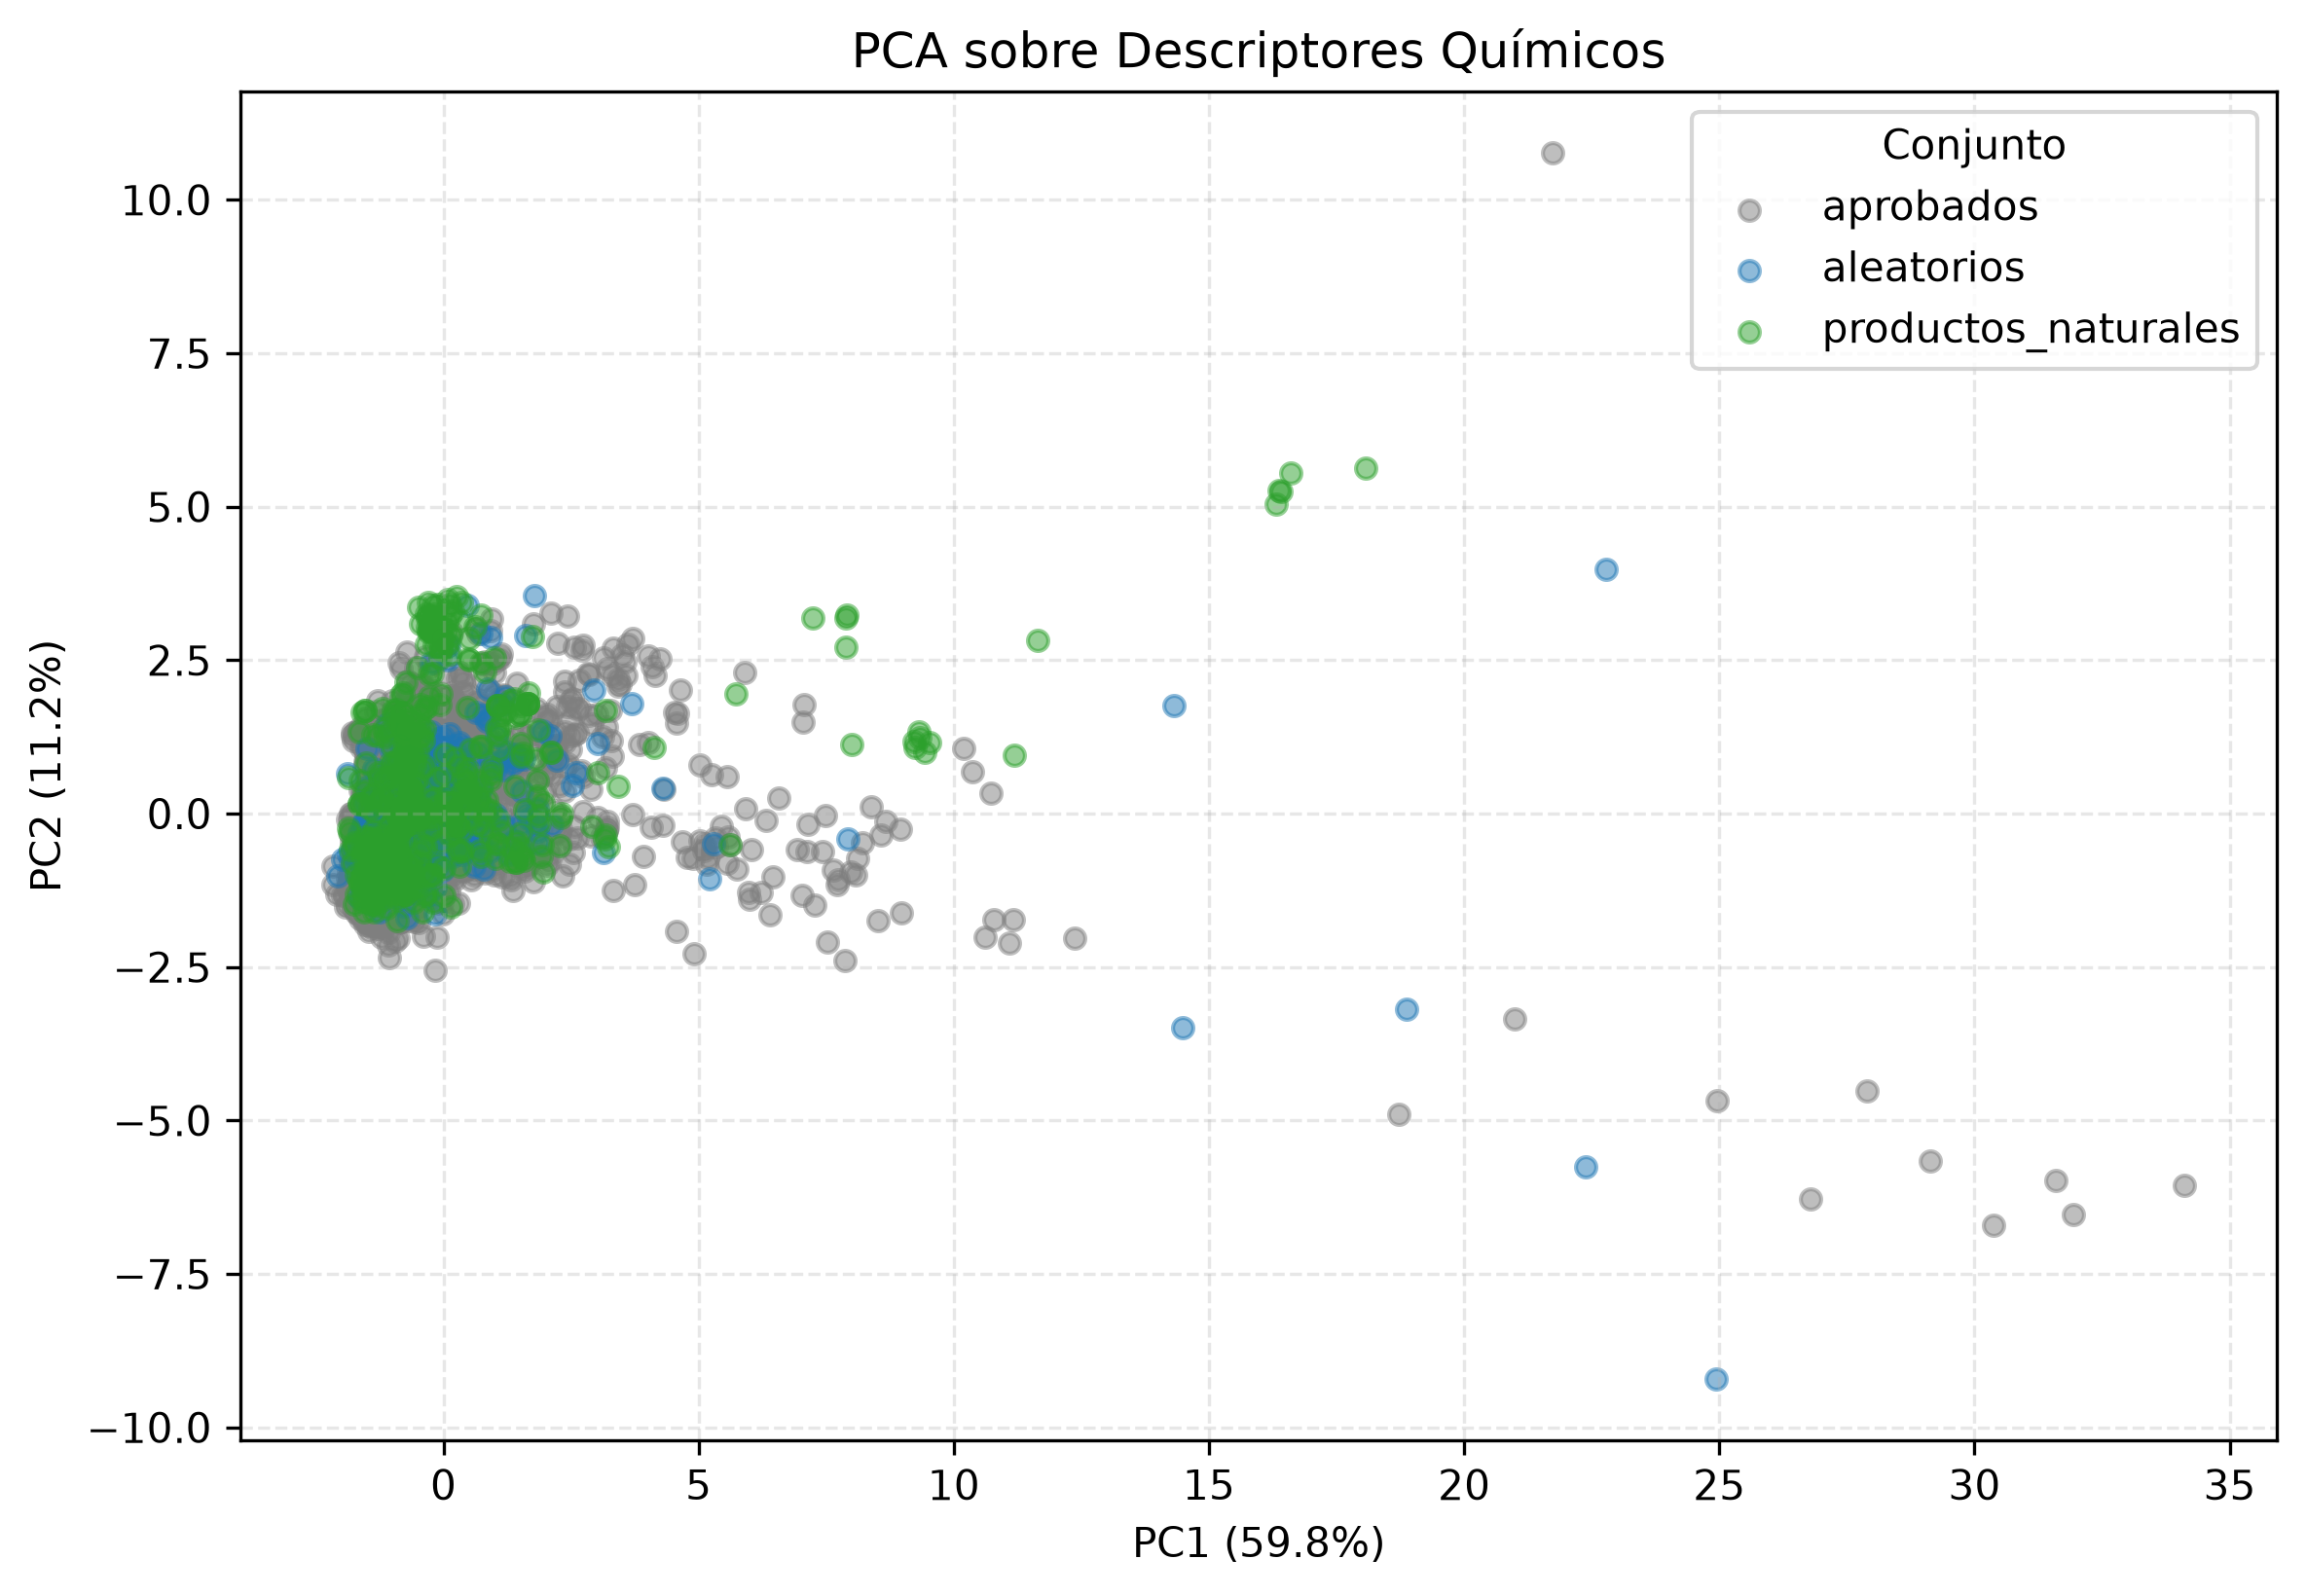

In [22]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# Crear directorio figures/ si no existe
os.makedirs("figures", exist_ok=True)

df_pca = pd.DataFrame({
    'PC1': coords[:, 0],
    'PC2': coords[:, 1],
    'conjunto': etiquetas
})

plt.figure(figsize=(9, 6), dpi=300)

# Orden de dibujo: conjunto más grande primero (al fondo) para evitar solapamiento
orden_dibujo = ['aprobados', 'aleatorios', 'productos_naturales']
colores = {'aprobados': '#7f7f7f', 'aleatorios': '#1f77b4', 'productos_naturales': '#2ca02c'}

for grupo in orden_dibujo:
    sub = df_pca[df_pca['conjunto'] == grupo]
    plt.scatter(sub['PC1'], sub['PC2'], label=grupo, alpha=0.5, s=25, color=colores[grupo])

# Varianza explicada explícita en los ejes
plt.xlabel(f"PC1 ({var[0]:.1f}%)")
plt.ylabel(f"PC2 ({var[1]:.1f}%)")
plt.title("PCA sobre Descriptores Químicos")
plt.legend(title="Conjunto")
plt.grid(True, linestyle='--', alpha=0.3)

# Guardar figura requerida en disco
ruta_pca = "/home/ratam/forkC2026/Bioinf-NatProd/figures/torresfig/figF2/espacio_quimico_pca.png"
plt.savefig(ruta_pca, dpi=300, bbox_inches='tight')
print(f"✓ Imagen de PCA guardada en: {ruta_pca}")

plt.show()

In [19]:
import numpy as np
import umap

# 1. Asegurar huellas ECFP4 (Morgan r=2, 2048 bits) en la columna unificada para todas las moléculas
todos['Morgan_FP_2048'] = todos['SMILES_UNIFICADO'].apply(
    lambda x: huella(x) if isinstance(x, str) else None
)

# 2. Extraer matriz 2D de huellas descartando nulos
df_umap = todos.dropna(subset=['Morgan_FP_2048']).copy()
huellas = np.vstack(df_umap['Morgan_FP_2048'].values)
etiquetas_umap = df_umap['conjunto'].values

# 3. Ajuste de UMAP con distancia Jaccard
reductor = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="jaccard", random_state=42)
coords_umap = reductor.fit_transform(huellas)

print(f"Dimensiones de la matriz de huellas ECFP4: {huellas.shape}")
print(f"Coordenadas UMAP generadas: {coords_umap.shape}")

/home/ratam/miniforge3/envs/quimioinf/lib/python3.11/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/home/ratam/miniforge3/envs/quimioinf/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Dimensiones de la matriz de huellas ECFP4: (3162, 2048)
Coordenadas UMAP generadas: (3162, 2)


✓ Imagen de UMAP guardada en: /home/ratam/forkC2026/Bioinf-NatProd/figures/torresfig/figF2/espacio_quimico_umap.png


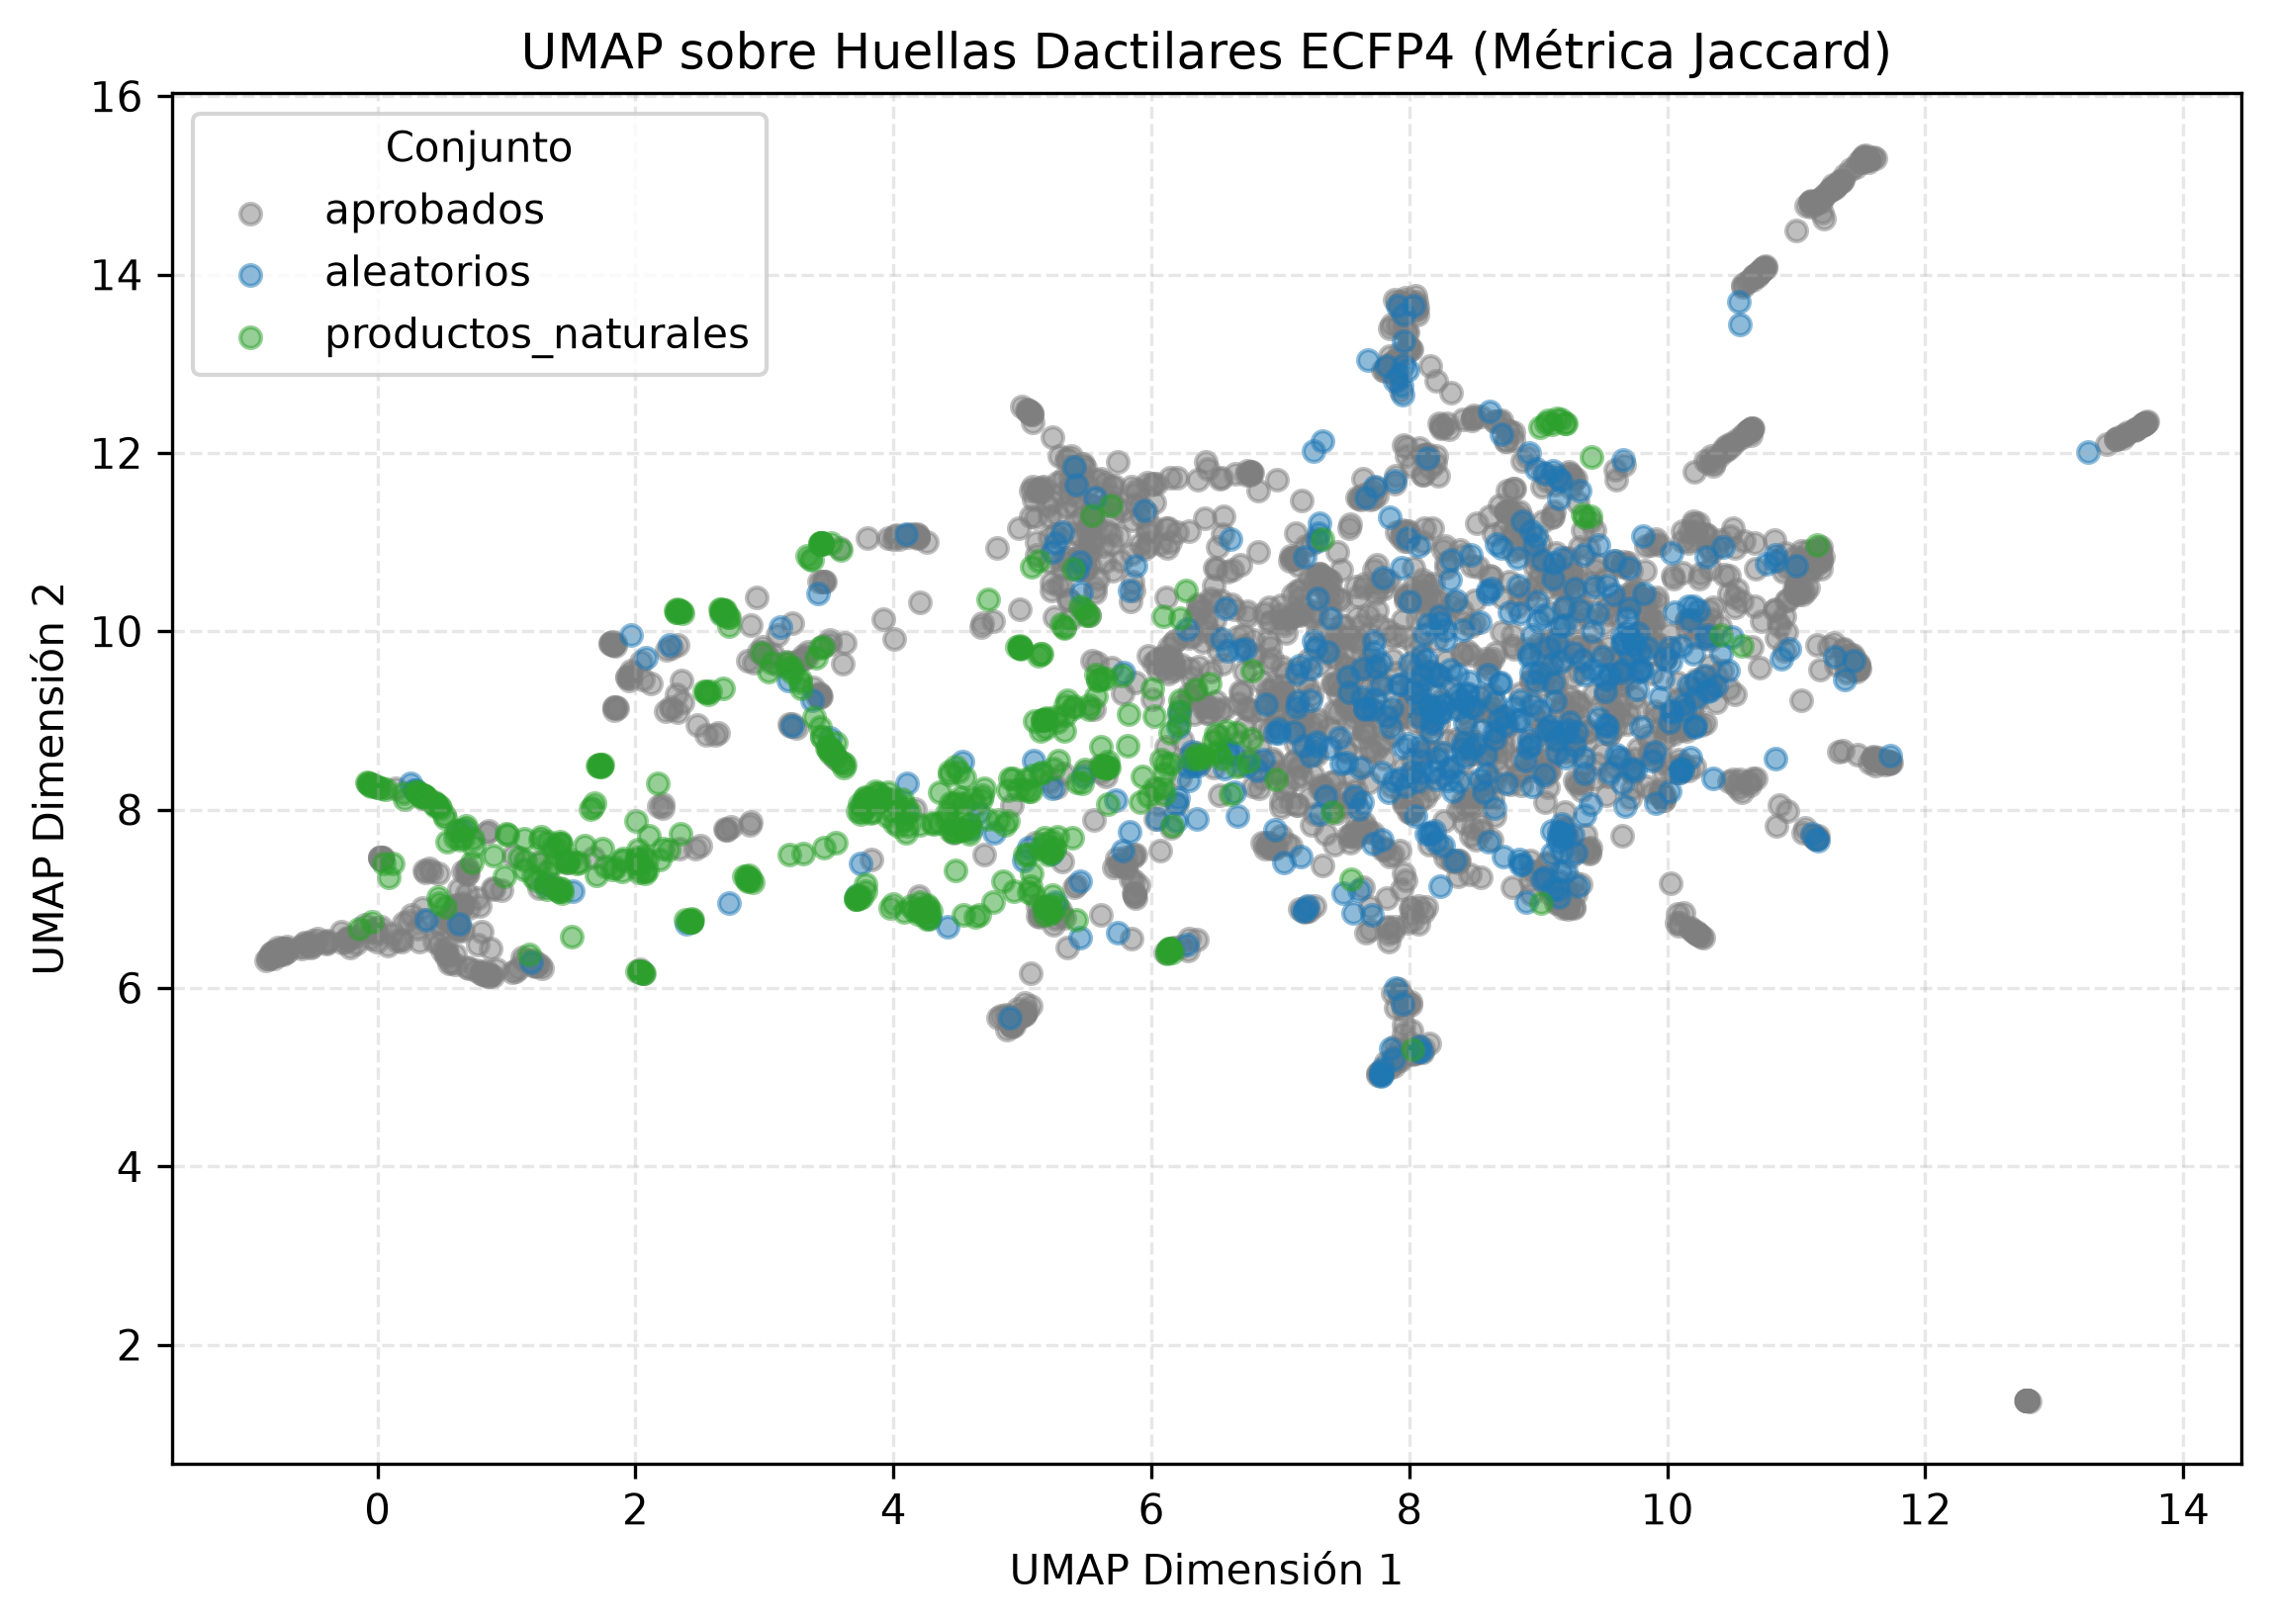

In [21]:
df_umap_plot = pd.DataFrame({
    'UMAP_1': coords_umap[:, 0],
    'UMAP_2': coords_umap[:, 1],
    'conjunto': etiquetas_umap
})

plt.figure(figsize=(9, 6), dpi=300)

for grupo in orden_dibujo:
    sub = df_umap_plot[df_umap_plot['conjunto'] == grupo]
    plt.scatter(sub['UMAP_1'], sub['UMAP_2'], label=grupo, alpha=0.5, s=25, color=colores[grupo])

plt.xlabel("UMAP Dimensión 1")
plt.ylabel("UMAP Dimensión 2")
plt.title("UMAP sobre Huellas Dactilares ECFP4 (Métrica Jaccard)")
plt.legend(title="Conjunto")
plt.grid(True, linestyle='--', alpha=0.3)

# Guardar figura requerida en disco
ruta_umap = "/home/ratam/forkC2026/Bioinf-NatProd/figures/torresfig/figF2/espacio_quimico_umap.png"
plt.savefig(ruta_umap, dpi=300, bbox_inches='tight')
print(f"✓ Imagen de UMAP guardada en: {ruta_umap}")

plt.show()